# Travelling salesman: simulated annealing

In [1]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt

# Générer des villes aléatoires
def generate_cities(n):
    return np.random.rand(n, 2) * 100

# Calcul de la distance totale d'un chemin
def total_distance(path, cities):
    return sum(np.linalg.norm(cities[path[i]] - cities[path[(i+1)%len(path)]]) for i in range(len(path)))

# Perturbation : échange de deux villes
def perturb(path):
    new_path = path[:]
    i, j = sorted(random.sample(range(len(path)), 2))
    new_path[i:j] = reversed(new_path[i:j])  # perturbation par inversion d’un sous-chemin
    return new_path

# Recuit simulé avec perturbation
def simulated_annealing_with_perturbation(cities, T_init, T_min=1e-3, alpha=0.99, max_iter=1000):
    path = list(range(len(cities)))
    random.shuffle(path)
    best_path = path[:]
    best_distance = total_distance(path, cities)

    T = T_init
    distances = [best_distance]

    for _ in range(max_iter):
        if T < T_min:
            break

        candidate = perturb(path)
        current_distance = total_distance(path, cities)
        candidate_distance = total_distance(candidate, cities)
        delta = candidate_distance - current_distance

        if delta < 0 or random.random() < math.exp(-delta / T):
            path = candidate
            if candidate_distance < best_distance:
                best_distance = candidate_distance
                best_path = candidate
        distances.append(best_distance)
        T *= alpha

    return best_path, best_distance, distances

In [2]:
cities = generate_cities(20)

# a. Température très élevée
_, dist_high, _ = simulated_annealing_with_perturbation(cities, T_init=1e6)
print(f"Température élevée (1e6) -> Distance: {dist_high:.2f}")

# b. Température très faible
_, dist_low, _ = simulated_annealing_with_perturbation(cities, T_init=0.01)
print(f"Température basse (0.01) -> Distance: {dist_low:.2f}")

# c. Étude comparative
temperatures = [1, 10, 100, 1000, 10000]
for T in temperatures:
    _, dist, _ = simulated_annealing_with_perturbation(cities, T_init=T)
    print(f"T = {T:<5} -> Distance: {dist:.2f}")


Température élevée (1e6) -> Distance: 675.80
Température basse (0.01) -> Distance: 495.41
T = 1     -> Distance: 381.09
T = 10    -> Distance: 456.32
T = 100   -> Distance: 363.55
T = 1000  -> Distance: 363.55
T = 10000 -> Distance: 370.82


In [3]:
import pandas as pn
import numpy as np
import math
import random

#Distance entre deux villes
def distance(p1,p2):
    return math.sqrt((p1[0]-p2[0])**2 + (p1[1]-p2[1])**2)


#Energie totale : fonction à minimiser
def energieTotale(trajet_coords):









    energie = 0.0
    N = len(trajet_coords)
    for numv in range(N-1): # on calcule la distance en fermant la boucle
      energie += distance(trajet_coords[numv],\
      trajet_coords[numv+1])
    energie += distance(trajet_coords[N-1],\
    trajet_coords[0])
    return energie

#Trouver un voisin
def perturbation(trajet):
  N = len(trajet)
  i = np.random.randint(N)
  j = i
  while (i==j):
    j = np.random.randint(N)
  nv = trajet[:]
  temp = nv[i]
  nv[i] = nv[j]
  nv[j] = temp

  return nv


def initialiser(nbVilles):
    return list(np.random.permutation(nbVilles))




[Itération 2] T = 980000.00 | Distance : 65.98
[Itération 3] T = 960400.00 | Distance : 59.04
[Itération 4] T = 941192.00 | Distance : 64.08
[Itération 5] T = 922368.16 | Distance : 57.02
[Itération 6] T = 903920.80 | Distance : 71.63
[Itération 7] T = 885842.38 | Distance : 57.63
[Itération 8] T = 868125.53 | Distance : 62.57
[Itération 9] T = 850763.02 | Distance : 66.18
[Itération 10] T = 833747.76 | Distance : 60.24
[Itération 11] T = 817072.81 | Distance : 55.02
[Itération 12] T = 800731.35 | Distance : 54.05
[Itération 13] T = 784716.72 | Distance : 72.57
[Itération 14] T = 769022.39 | Distance : 64.31
[Itération 15] T = 753641.94 | Distance : 48.44
[Itération 16] T = 738569.10 | Distance : 71.18
[Itération 17] T = 723797.72 | Distance : 59.48
[Itération 18] T = 709321.77 | Distance : 68.39
[Itération 19] T = 695135.33 | Distance : 53.99
[Itération 20] T = 681232.62 | Distance : 57.80
[Itération 21] T = 667607.97 | Distance : 54.68
[Itération 22] T = 654255.81 | Distance : 62.74


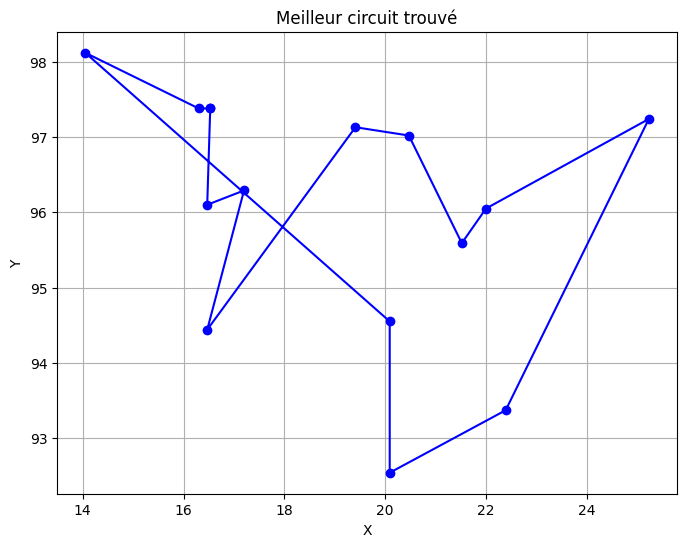

In [9]:
import pandas as pn
import numpy as np
import math
import random
import matplotlib.pyplot as plt

# --- FONCTIONS DE BASE ---

def distance(p1, p2):
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

def energieTotale(trajet_coords):
    energie = 0.0
    N = len(trajet_coords)
    for numv in range(N - 1):
        energie += distance(trajet_coords[numv], trajet_coords[numv + 1])
    energie += distance(trajet_coords[N - 1], trajet_coords[0])
    return energie

def perturbation(trajet):
    N = len(trajet)
    i = np.random.randint(N)
    j = i
    while i == j:
        j = np.random.randint(N)
    nv = trajet[:]
    nv[i], nv[j] = nv[j], nv[i]
    return nv

def initialiser(nbVilles):
    return list(np.random.permutation(nbVilles))


# --- LECTURE DES VILLES ---
df_villes = pn.read_csv('14.tsp')  # Assurez-vous que ce fichier existe
nbVilles = len(df_villes)
trajet = initialiser(nbVilles)
trajet_coords = [(df_villes['x'][i], df_villes['y'][i]) for i in trajet]
energie = energieTotale(trajet_coords)

# --- PARAMÈTRES ---
T0 = 1_000_000
Tmin = 1
alpha = 0.98
nbIterations = 10_000_000
Palier = 5

T = T0
numiter = 1

trajet_min = trajet
energie_min = energie
distance_initiale = energie

# Compteurs
nb_ameliore = 0
nb_explore = 0
nb_total = 0
liste_energies = [energie]  # pour graphe éventuel


# --- ALGORITHME DE RECUIT SIMULÉ ---
while T > Tmin and numiter < nbIterations:
    iterPalier = Palier
    while iterPalier > 0:
        iterPalier -= 1

        trajet_vois = perturbation(trajet)
        trajet_vois_coord = [(df_villes['x'][i], df_villes['y'][i]) for i in trajet_vois]
        energie_vois = energieTotale(trajet_vois_coord)

        Delta_energie = energie_vois - energie

        if Delta_energie < 0:
            trajet = trajet_vois
            trajet_coords = trajet_vois_coord
            energie = energie_vois
            nb_ameliore += 1
            if energie < energie_min:
                trajet_min = trajet
                energie_min = energie
        else:
            metropol = math.exp(-Delta_energie / T)
            val = np.random.random()
            if val < metropol:
                trajet = trajet_vois
                trajet_coords = trajet_vois_coord
                energie = energie_vois
                nb_explore += 1

        nb_total += 1
        liste_energies.append(energie_min)

    T *= alpha
    numiter += 1
    print(f"[Itération {numiter}] T = {T:.2f} | Distance : {energie:.2f}")

# --- AFFICHAGE FINAL ---

print("\n--- RÉSULTATS FINAUX ---")
print(f"Distance initiale           : {distance_initiale:.2f}")
print(f"Meilleur circuit trouvé     : {trajet_min}")
print(f"Longueur du meilleur circuit: {energie_min:.2f}")
print(f"Nombre d'itérations totales : {numiter}")
print(f"Taux d'amélioration         : {nb_ameliore / nb_total * 100:.2f}%")
print(f"Taux d'exploration          : {nb_explore / nb_total * 100:.2f}%")

# --- VISUALISATION DU MEILLEUR TRAJET ---
def afficher_circuit(trajet, df):
    coords = [(df['x'][i], df['y'][i]) for i in trajet]
    coords.append(coords[0])  # retour au point de départ
    xs, ys = zip(*coords)
    plt.figure(figsize=(8,6))
    plt.plot(xs, ys, marker='o', linestyle='-', color='blue')
    plt.title("Meilleur circuit trouvé")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(True)
    plt.show()

afficher_circuit(trajet_min, df_villes)

# --- VISUALISATION DE L'ÉVOLUTION DE L'ÉNERGIE (optionnelle) ---
def afficher_evolution_energie(energies):
    plt.figure(figsize=(8,4))
    plt.plot(energies)
    plt.title("Évolution de la meilleure distance")
    plt.xlabel("Itération")
    plt.ylabel("Distance")
    plt.grid(True)
    plt.show()

# Décommente si tu veux afficher l'évolution :
# afficher_evolution_energie(liste_energies)


[Itération 2] T = 990000.00 | Distance : 56.54
[Itération 3] T = 980100.00 | Distance : 60.53
[Itération 4] T = 970299.00 | Distance : 59.04
[Itération 5] T = 960596.01 | Distance : 57.20
[Itération 6] T = 950990.05 | Distance : 58.12
[Itération 7] T = 941480.15 | Distance : 56.75
[Itération 8] T = 932065.35 | Distance : 58.30
[Itération 9] T = 922744.69 | Distance : 73.82
[Itération 10] T = 913517.25 | Distance : 53.04
[Itération 11] T = 904382.08 | Distance : 55.57
[Itération 12] T = 895338.25 | Distance : 61.36
[Itération 13] T = 886384.87 | Distance : 59.16
[Itération 14] T = 877521.02 | Distance : 53.20
[Itération 15] T = 868745.81 | Distance : 59.98
[Itération 16] T = 860058.35 | Distance : 61.24
[Itération 17] T = 851457.77 | Distance : 59.81
[Itération 18] T = 842943.19 | Distance : 57.86
[Itération 19] T = 834513.76 | Distance : 48.26
[Itération 20] T = 826168.62 | Distance : 50.19
[Itération 21] T = 817906.94 | Distance : 64.65
[Itération 22] T = 809727.87 | Distance : 69.74


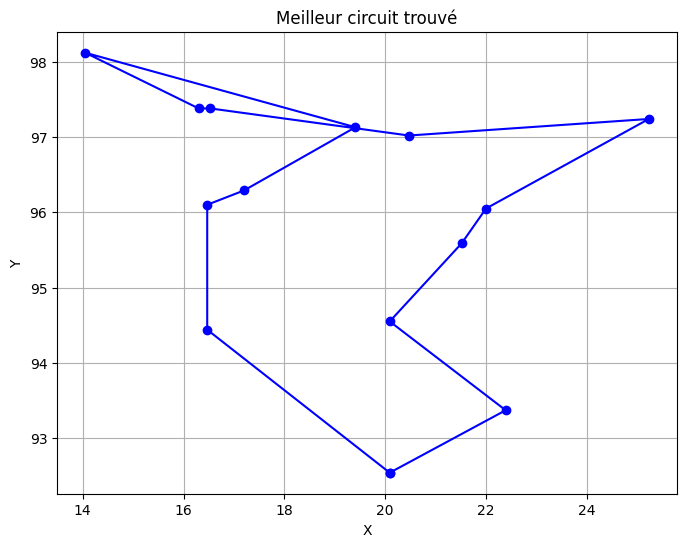

In [3]:
import pandas as pn
import numpy as np
import math
import random
import matplotlib.pyplot as plt

# --- FONCTIONS DE BASE ---

def distance(p1, p2):
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

def energieTotale(trajet_coords):
    energie = 0.0
    N = len(trajet_coords)
    for numv in range(N - 1):
        energie += distance(trajet_coords[numv], trajet_coords[numv + 1])
    energie += distance(trajet_coords[N - 1], trajet_coords[0])
    return energie

def perturbation(trajet):
    N = len(trajet)
    i = np.random.randint(N)
    j = i
    while i == j:
        j = np.random.randint(N)
    nv = trajet[:]
    nv[i], nv[j] = nv[j], nv[i]
    return nv

def initialiser(nbVilles):
    return list(np.random.permutation(nbVilles))


# --- LECTURE DES VILLES ---
df_villes = pn.read_csv('14.tsp')
nbVilles = len(df_villes)
trajet = initialiser(nbVilles)
trajet_coords = [(df_villes['x'][i], df_villes['y'][i]) for i in trajet]
energie = energieTotale(trajet_coords)

# --- PARAMÈTRES ---
T0 = 1_000_000
Tmin = 1
alpha = 0.99
nbIterations = 10_000_000
Palier = 5

T = T0
numiter = 1

trajet_min = trajet
energie_min = energie
distance_initiale = energie

# --- COMPTEURS (style du prof) ---
cpt_iter = 0
cpt_iter_tot = 0
cpt_explo = 0
cpt_explo1 = 0
cpt_explo2 = 0
cpt_amel = 0

# --- ALGO ---
while T > Tmin and numiter < nbIterations:
    iterPalier = Palier
    while iterPalier > 0:
        iterPalier -= 1
        cpt_iter += 1
        cpt_iter_tot += 1

        trajet_vois = perturbation(trajet)
        trajet_vois_coord = [(df_villes['x'][i], df_villes['y'][i]) for i in trajet_vois]
        energie_vois = energieTotale(trajet_vois_coord)

        Delta_energie = energie_vois - energie

        if Delta_energie < 0:
            trajet = trajet_vois
            trajet_coords = trajet_vois_coord
            energie = energie_vois
            cpt_amel += 1
            if energie < energie_min:
                trajet_min = trajet
                energie_min = energie
        else:
            metropol = math.exp(-Delta_energie / T)
            val = np.random.random()
            if val < metropol:
                # Conditions des 10 % du début ou fin
                if cpt_iter <= 0.1 * cpt_iter_tot:
                    cpt_explo1 += 1
                elif cpt_iter >= 0.9 * cpt_iter_tot:
                    cpt_explo2 += 1

                cpt_explo += 1
                trajet = trajet_vois
                trajet_coords = trajet_vois_coord
                energie = energie_vois

    T *= alpha
    numiter += 1
    print(f"[Itération {numiter}] T = {T:.2f} | Distance : {energie:.2f}")

# --- AFFICHAGE FINAL ---
print("\n--- RÉSULTATS FINAUX ---")
print(f"Distance initiale           : {distance_initiale:.2f}")
print(f"Meilleur circuit trouvé     : {trajet_min}")
print(f"Longueur du meilleur circuit: {energie_min:.2f}")
print(f"Nombre total d'itérations   : {cpt_iter_tot}")
print(f"Nombre d'améliorations      : {cpt_amel}")
print(f"Nombre d'explorations       : {cpt_explo}")
print(f" - Dont dans les 10% débuts : {cpt_explo1}")
print(f" - Dont dans les 10% fins   : {cpt_explo2}")

# --- VISUALISATION DU MEILLEUR TRAJET ---
def afficher_circuit(trajet, df):
    coords = [(df['x'][i], df['y'][i]) for i in trajet]
    coords.append(coords[0])
    xs, ys = zip(*coords)
    plt.figure(figsize=(8,6))
    plt.plot(xs, ys, marker='o', linestyle='-', color='blue')
    plt.title("Meilleur circuit trouvé")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(True)
    plt.show()

afficher_circuit(trajet_min, df_villes)
